# Linear regressions

In this section we will focus on **regression models**, that's any machine learning model that allow us to estimate a numerical and **continuous** target variable. We will focus on the concrete example of real estate prices in Boston, using a dataset provided in the scikit learn package from python.



## What will you learn in this course? 🧐🧐

This course will give you the theoretical background you need to understand linear regression models.

* Simple linear regressions
    * Definitions
        * Dependent variables
        * Independent Variables
        * Coefficient
        * Constant
        * Residual
* Assumptions behind linear regression
    * Linearity
    * Homoscedasticity
    * Independence of residuals
* Estimation
    * The ordinary least square method (commonly referred to as OLS)
        * Definition
* Multiple linear regression
    * Definition
        * Plurality of independent variables
    * Normalizing the variables
    * Mathematical notation of the problem
    * Variance/Covariance Matrix
* Assumptions for multiple linear regression
    * Everything in simple linear regression plus NO collinearity
    * Dummy Variables
        * Reminder: Categorical variables
        * Encode categorical variables
        * The dummy variable trap
* Final remarks

## Simple linear regressions 🧸

### Definition

Simple linear regression models are based on the following linear equation :

$$
Y = \beta_{0} + \beta_{1}X_1 + \epsilon
$$

Here, $Y$ represents the target variable, i.e. the variable whose value we wish to estimate, $X_1$ is the explanatory variable we have chosen to estimate the target variable. $\beta_0$, $\beta_{1}$, and $\epsilon$ are respectively the intercept (i.e. level 0 of $Y$ when $X$ is 0), the coefficient associated with $X_1$ (it is the parameter of the model that measures the influence of $X_1$ on $Y$, if $X_1$ increases by 1, $Y$ will increase by $\beta_{1}$), and the error or residue of the model. The above equation is the representation of a statistical model: it is true on average but does not claim to be exact, which explains the presence of the residual $\epsilon$.

Depending on the samples in your dataset (see scatter plot below), your model will find the line that comes as close as possible to all the dots on average. Here's what it looks like visually:

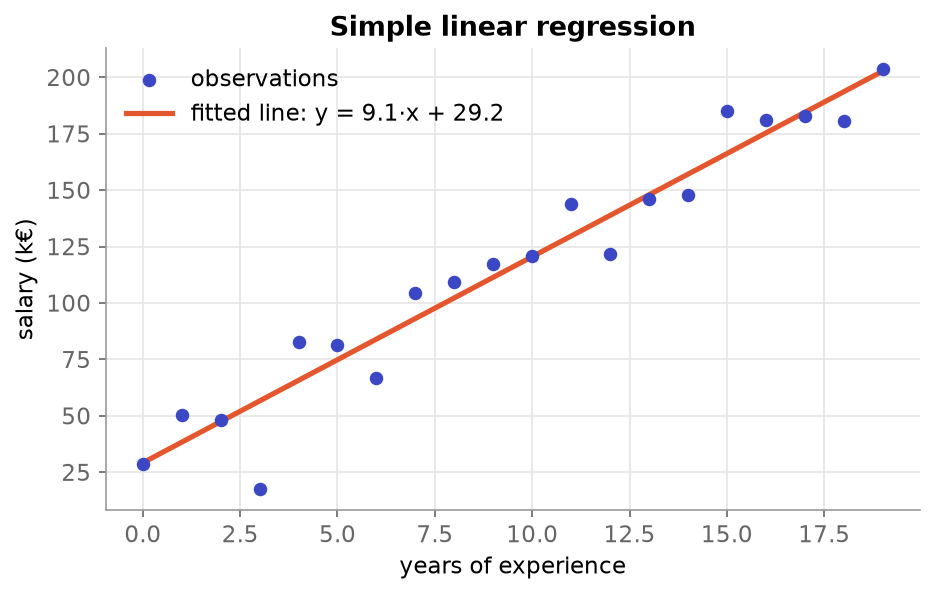

#### Dependent variables

In Machine Learning, we always distinguish between the **dependent variable/target variable** and **independent variables/explanatory variables.** The dependent variable is the element you are trying to predict. In the equation above, this corresponds to $Y$.

#### Independent Variables

The independent variables, represented by $X_i$ ($i$ is an index that indicates the position of the column in a dataset) are your predictors that will be used to determine the value of $Y$. For example, if we try to predict someone's salary based on their years of experience. The independent variable $X_i$ corresponds to the number of years of experience.

#### Coefficient

The $\beta_{1}$ coefficient represents the _slope_ of the regression line or the weight your independent variable will have in your equation. Like we mentionned before, the practical interpretation of $\beta_1$ is the following : if $X_1$ increases by $1$, $Y$ is **expected** to increase by $\beta_1$. The term **expected** is really important here, remember that any machine learning model is meant to be statistically as good as possible, which means that it needs to perform best on average across all given training samples and does not necessarily predict all individual samples perfectly.

#### Constant

Finally, the constant $\beta_{0}$ represents where your line will start if $X_1 = 0$. In the context of predicting wages in relation to years of experience, even at 0 years of experience ($X_1 = 0$), the starting minimum wage will be expected to be different from 0.

#### Residual

The residual, often noted $\epsilon$ corresponds to the error. It represents all the information that is not explained by the model. It is often assumed that the error follows a particular law of probability in order to justify modeling the data with specific kinds of machine learning models.


## Assumptions behind linear regression ☝️

When building an ML model, you should be aware of the assumptions you are making in order for your model to work well. Otherwise, you will have a poor performance. Remember that traditional machine learning is all based on statistics, which is a sub-section of mathematics, and is an **exact** science, therefore all models that we will study in this module are backed by statistical theory and mathematical proofs that define the theoretical context in which the model can be optimised with certainty. It is very common for these assumptions not to be true in practical contexts, however in most cases, models can still be used, and derive useful results despite all hypothesis not being verified. The assumptions needed for a simple linear regression model are the following:

### Linearity

The first assumption is simple. You need your points to follow roughly a straight line. In other words, you need to ensure that your dependent variable varies linearly as your independent variables increase.

### Homoscedasticity

Assuming the first assumption is holding and your samples follow a linear dependence between $Y$ and $X_1$, homoscedasticity introduces an assumption on the statistical distribution of the residual $\epsilon$. Homoscedasticity means that your residuals need to show constant variance accross all possible values of $Y$. If $\epsilon$ take small values when $Y$ is small and large values when $Y$ is large, then homoscedasticity is not verified.

This hypothesis is important in theory in order to mathematically solve the linear regression equation we will introduce, however it does not prevent your model to prove useful in practice.

### Independence of residuals

The residuals need to be independent from each other. Independence is a very difficult characteristic to verify in practice, therefore it is frequently replaced with absence of autocorrelation (which means correlation with itself). For example if residuals for small values of $Y$ tend to be all negative and residuals for larger values of $Y$ tend to be all positive, that indicates autocorrelation of residuals, which we wish to avoid.


## Estimation 🔧

Estimation techniques are the methods that we use to calculate the optimal parameters of the model so the residuals are as little as possible accross all data. Here we will introduce one technique that can be used to optimize a simple linear regression model. You do not need to know this by heart but rather understand the general logic behind it which roughly goes as follows: we choose a function that needs to be minimized or maximized, which is directly linked to the model's equation. This function is called the loss function when we need to minimize it, and the likelihood when we need to maximize it (explanations regarding likelihood can be found in the optional lecture). Loss functions usually represent the "cost" of prediction errors that we wish to minimize and the likelihood is a probability distribution connecting the target variable to the explanatory variables.

### The ordinary least square method (commonly referred to as OLS)

#### Definition

You are probably wondering how we know that the line in our model is the one that is the "closest" to each of the points in our dataset. Well, it's because of the "ordinary least square" method. We're not going to demonstrate the method all the way. What you have to understand is that the algorithm will look for the minimum possible distance between each point in your graph using this optimization problem:

$$
Min (\sum_{i=1}^{n}(y_{i}-\hat{y}_{i})^2)
$$

We are looking for the set of parameters that will minimize the sum of square errors between the target variable and the prediction. This is actually your first encounter with a **loss function**.

$$
Min (\sum_{i=1}^{n}(y_{i}-\beta_{0}-\beta_{1}x_{i})^2)
$$

In this equation, $y_{i}$ represents the value of the target variable $Y$ for each sample (or row) in your dataset while $\hat{y}_{i}$ represents your model's prediction.

After several iterations, your algorithm is able to minimize this equation and find the best set of parameters given your training data.

:::note Whats is the best optimization technique ?
In the case of simple linear regression, maximum likelihood or least square estimation is equivalent in terms of finding the optimal set of parameters. However the concept of loss function is becoming more popular, expecially with the rise of deep learning.
:::

## Multiple linear regression 🏋️

### Definition

#### Plurality of independent variables

Most of the time, you will not want to choose just one variable in order to predict your target variable. For example, you can predict someone's salary with the number of years of experience, but you can also use the type of degree, the sector in which the person works, the gender, the country of residence, and so on.

This is the only difference between single and multiple linear regression. You add independent variables into the equation.

### Normalizing the variables

A major step when preparing your data for prediction is normalization, when should you (or should you not) normalize your data. Well it highly depends on the type of model you are going to use for prediction and the type of analysis you wish to make.

Normalization is not needed for multiple linear regression because linear functions treat all variables similarly regardless of scale. A variable like salary described in thousands of euros will have the same effect on the loss function when it varies compared to a variable like age that takes values between 1 and 100 roughly.

When you choose not to normalize your data before running a linear regression model, it means that the parameters $\beta$ in your model can be interpreted directly, meaning if my age variable varies by 1 it means my sample is one year older, then my $Y$ variable, for example salary, will vary by $beta_{age}$. The downside is that the values of the parameters cannot be compared with one another, because each parameters value will depend on the representation scale of the corresponding variable.

If you normalize your data the parameters of the model can be compared with one another because all of your variables are represented on the same scale. Then a variation of 1 on $X_{1\_scaled}$ has an effect of $\beta_1$ on $Y$ and represents a variation of $\sigma_{X_1}$ on $X_1$.

### Mathematical notation of the problem

By noting $Y$ the target variable, $X_1, X_2, ..., X_n$ the explanatory variables, $\beta_{i}$ the model parameters and $\epsilon$ the vector of residuals, the multiple linear regression model is written :

$$
Y_{i} = \beta_{0}+X_{i,1}\beta_{1}+...+X_{i,p}\beta_{p}+\epsilon_{i}\forall i \in \left [1,n \right ]
$$


You can also write the problem in matrix form as follows:

$$
Y=X \times \beta+\epsilon
$$


Where $Y$ is a vector of $(n, 1)$ dimensions, $X$ is a matrix of $(n, p + 1)$ dimensions, $\beta$ is a vector of $(p + 1, 1)$ dimensions and $\epsilon$ is a vector of $(n,1)$ dimensions.




## Assumptions for multiple linear regression ☝️

### Everything in simple linear regression plus NO collinearity

As you can already imagine, multiple linear regressions will depend on the same assumptions as simple linear regressions because, after all, you just add a bit of complexity. The only thing you need to add in the assumptions is the _non-colinearity_ of the independent variables.

For example, if you are trying to predict someone's salary based on their age and birth year, you will run into a problem. Indeed a linear realtion exists between age and birth year : $age = current\_year - birth\_year$.

In general, given a collection of variables $X_1, X_2, ..., X_k$, these variable are collinear if and only if you can find a constant $c$ and a collection of constants $\lambda_1, \lambda_2, ..., \lambda_k$ not all equal to zero such that $\lambda_1 \times X_1 + \lambda_2 \times X_2 + ... + \lambda_k \times X_k = c$.

If you have collinearity in your model, you won't be able to fit a linear regression model. 

:::tip Reminder: To check multicollinearity, you need to build a [correlation matrix](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) that is based on the [covariance matrix](https://en.wikipedia.org/wiki/Covariance_matrix). Check out your course on EDA to get a clear reminder 😉 
:::

### Dummy Variables

#### Reminder: Categorical variables

To understand what dummy variables are, let us first recall what categorical variables are: they are simply qualitative data. For example, think about countries, colors, etc.

#### Encode categorical variables

In machine learning, you cannot use non numerical variables for training the model. This is why categorical variables are encoded and replaced by a collection of what we call dummy variables that take values of either 0 or 1.

#### The dummy variable trap

Once you have encoded your dummy variables, you won't add them all into your equation because you will have a collinearity problem between your dummy variables, they all sum to one. So you will add all the dummy variables except one.

### Final Notes

Linear models are very sensitive to extreme values that may be present in a dataset, so pre-processing your learning base is essential to avoid having your results completely skewed.

## Resources 📚📚

* Introduction to Simple Linear Regression - https://www.youtube.com/watch?v=KsVBBJRb9TE
* Statistics How to Simple Linear Regression - https://www.statisticshowto.com/probability-and-statistics/regression-analysis/find-a-linear-regression-equation/
* Multiple Linear Regression Yale - http://www.stat.yale.edu/Courses/1997-98/101/linmult.htm
* What is Multiple Linear Regression - https://www.statisticssolutions.com/free-resources/directory-of-statistical-analyses/what-is-multiple-linear-regression/
